In [1]:
import matplotlib.pyplot as plt
from qiskit.visualization import plot_histogram
import numpy as np
from qiskit import QuantumCircuit, QuantumRegister
import time
from functools import partial
from qiskit.result import Counts
from collections import Counter
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import EfficientSU2, ExcitationPreserving
from qiskit.compiler import transpile
from qiskit.quantum_info import SparsePauliOp, Operator
from qiskit.primitives import StatevectorEstimator
from qiskit.transpiler import CouplingMap
%matplotlib inline
import openfermion as of

from iqm import qiskit_iqm
from iqm.qiskit_iqm.fake_backends import fake_aphrodite
from iqm.qiskit_iqm.iqm_transpilation import optimize_single_qubit_gates, IQMOptimizeSingleQubitGates
from qiskit_ibm_runtime import Estimator, Session, Options, Batch

from typing import List
from scipy.optimize import minimize, dual_annealing, basinhopping, cobyla, BFGS
from qiskit_algorithms.optimizers import SPSA
from qiskit.result import CorrelatedReadoutMitigator
import scipy.linalg as la

from iqm.qiskit_iqm import IQMProvider
import os

import sys
sys.path.append(os.path.abspath('..'))
from Learning_Algorithm.learning_algorithm_REM import Learning

In [2]:
# Setting backend 
fake_backend = fake_aphrodite.IQMFakeAphrodite()
target = fake_backend.target

#Q50_CORTEX_URL = os.getenv('Q50_CORTEX_URL')
#Q50_provider = IQMProvider(Q50_CORTEX_URL)
#fake_backend = Q50_provider.get_backend()
# target = fake_backend.target

In [3]:
# Hubbard parameters
N_x = 1            # lattice sites in x-direction
N_y = 3            # lattice sites in y-direction
N = N_x * N_y
U = 50             # repulsive on-site interaction
t = 1.0            # kinetic energy

layout = [4,5,6,10,11,12]   # choice of qubits to use

In [4]:
# Hubbard Hamiltonian
hubbard_hamiltonian = of.fermi_hubbard(N_x, N_y, tunneling=t, coulomb=U, chemical_potential=U/2, periodic=False)
print("\n Hubbard Hamiltonian: \n", hubbard_hamiltonian)


 Hubbard Hamiltonian: 
 -25.0 [0^ 0] +
50.0 [0^ 0 1^ 1] +
-1.0 [0^ 2] +
-25.0 [1^ 1] +
-1.0 [1^ 3] +
-1.0 [2^ 0] +
-25.0 [2^ 2] +
50.0 [2^ 2 3^ 3] +
-1.0 [2^ 4] +
-1.0 [3^ 1] +
-25.0 [3^ 3] +
-1.0 [3^ 5] +
-1.0 [4^ 2] +
-25.0 [4^ 4] +
50.0 [4^ 4 5^ 5] +
-1.0 [5^ 3] +
-25.0 [5^ 5]


In [5]:
# Jordan-Wigner transformation
pauli_hubbard_hamiltonian = of.transforms.jordan_wigner(hubbard_hamiltonian)
print("\n Hubbard Hamiltonian in Pauli basis: \n", pauli_hubbard_hamiltonian)
print("\n List of terms: \n", pauli_hubbard_hamiltonian.terms)


 Hubbard Hamiltonian in Pauli basis: 
 (-37.5+0j) [] +
(-0.5+0j) [X0 Z1 X2] +
(-0.5+0j) [Y0 Z1 Y2] +
(12.5+0j) [Z0 Z1] +
(-0.5+0j) [X1 Z2 X3] +
(-0.5+0j) [Y1 Z2 Y3] +
(-0.5+0j) [X2 Z3 X4] +
(-0.5+0j) [Y2 Z3 Y4] +
(12.5+0j) [Z2 Z3] +
(-0.5+0j) [X3 Z4 X5] +
(-0.5+0j) [Y3 Z4 Y5] +
(12.5+0j) [Z4 Z5]

 List of terms: 
 {((0, 'Y'), (1, 'Z'), (2, 'Y')): (-0.5+0j), ((0, 'X'), (1, 'Z'), (2, 'X')): (-0.5+0j), ((1, 'Y'), (2, 'Z'), (3, 'Y')): (-0.5+0j), ((1, 'X'), (2, 'Z'), (3, 'X')): (-0.5+0j), ((0, 'Z'), (1, 'Z')): (12.5+0j), ((2, 'Y'), (3, 'Z'), (4, 'Y')): (-0.5+0j), ((2, 'X'), (3, 'Z'), (4, 'X')): (-0.5+0j), ((3, 'Y'), (4, 'Z'), (5, 'Y')): (-0.5+0j), ((3, 'X'), (4, 'Z'), (5, 'X')): (-0.5+0j), ((2, 'Z'), (3, 'Z')): (12.5+0j), (): (-37.5+0j), ((4, 'Z'), (5, 'Z')): (12.5+0j)}


In [6]:
# Converting Hamiltonian from openfermion to Qiskit SparsePauliOp
def openfermion_to_sparsepauliop(N, qubit_op):
    labels = []
    coeffs = []

    # Get number of qubits by checking all indices in terms
    max_index = 0
    for term in qubit_op.terms:
        for qubit, _ in term:
            if qubit > max_index:
                max_index = qubit
    n_qubits = max_index + 1

    for term, coeff in qubit_op.terms.items():
        label = ['I'] * 2*N
        for qubit, pauli in term:
            label[qubit] = pauli
        labels.append(''.join(reversed(label)))
        coeffs.append(complex(coeff))

    return SparsePauliOp(labels, coeffs=np.array(coeffs))

# Final Hubbard Hamiltonian
hamiltonian1 = openfermion_to_sparsepauliop(N, pauli_hubbard_hamiltonian)
print(hamiltonian1)

SparsePauliOp(['IIIYZY', 'IIIXZX', 'IIYZYI', 'IIXZXI', 'IIIIZZ', 'IYZYII', 'IXZXII', 'YZYIII', 'XZXIII', 'IIZZII', 'IIIIII', 'ZZIIII'],
              coeffs=[ -0.5+0.j,  -0.5+0.j,  -0.5+0.j,  -0.5+0.j,  12.5+0.j,  -0.5+0.j,
  -0.5+0.j,  -0.5+0.j,  -0.5+0.j,  12.5+0.j, -37.5+0.j,  12.5+0.j])


In [7]:
# Half-filled initial state
def half_filled_initial_state(n_qubits, n_particles):
    qc = QuantumCircuit(n_qubits)
    for i in range(n_particles):
        qc.x(i)
    return qc

initial_state = half_filled_initial_state(2*N, N)

In [8]:
# Physically inspired adapted SU(3) fermion ansatz
def givens_rotation(circuit, i, j, theta):
    # Applies a number-conserving Givens rotation between qubits i and j
    circuit.ry(-np.pi / 2, j)
    circuit.cx(i, j)
    circuit.ry(theta, j)
    circuit.cx(i, j)
    circuit.ry(np.pi / 2, j)

In [9]:
def fermionic(filling, N, layers):
    """
        filling: number of occupied modes for spin up/down as a list, for example [2, 2] is 2 spin up electrons, 2 spin down electrons
        N: number of spatial sites
        layers: number of ansatz layers
    """
    nqubits = 2 * N
    circuit = QuantumCircuit(nqubits)
    theta = ParameterVector('r', 5 * layers * (nqubits - 1))
    k = 0

    # Initial state preparation based on filling
    for color, n_particles in enumerate(filling):
        count = 0
        for site in range(N):
            if count < n_particles:
                qubit = color * N + site
                circuit.x(qubit)
                count += 1

    # Variational layers of Givens Rotations
    for layer in range(layers):
        # Even layer
        for i in range(0, nqubits - 1, 2):
            givens_rotation(circuit, i, i + 1, theta[k])
            k += 1
        # Odd layer
        for i in range(1, nqubits - 1, 2):
            givens_rotation(circuit, i, i + 1, theta[k])
            k += 1
        # Spin-up-spin-down entanglers 
        for i in range(N):
            q_up = i
            q_down = i + N
            givens_rotation(circuit, q_up, q_down, theta[k])
            k += 1
    return circuit

ansatz_fermionic = fermionic([1, 1], N, 1)

In [10]:
def hva_ansatz(N, layers):
    """
        N: number of spatial sites
        layers: number of HVA circuit layers
    """
    n_qubits = 2 * N                                           # 2N qubits for N electrons
    circuit = QuantumCircuit(n_qubits)
    theta_t = ParameterVector('θ_t', layers * (n_qubits - 1))  # hopping terms
    theta_u = ParameterVector('θ_u', layers * N)               # interaction terms
    k_t = 0
    k_u = 0

    # Initial state
    circuit.x(0)
    circuit.x(N)

    # HVA layers
    for l in range(layers):
        # Hopping terms
        for i in range(0, n_qubits - 1):
            givens_rotation(circuit, i, i + 1, theta_t[k_t])
            k_t += 1

        # On-site interaction terms
        for site in range(N):
            q_down = site
            q_up = site + N
            circuit.rzz(theta_u[k_u], q_down, q_up)
            k_u += 1

    return circuit

In [11]:
ansatz_SU2 = EfficientSU2(2*N, reps=1, su2_gates="r", entanglement="circular")

ansatz_HVA_custom = hva_ansatz(N, 1)

# Setting ansatz and estimator
ansatz1 = initial_state.compose(ansatz_SU2)
print("Ansatz qubit count:", ansatz1.num_qubits)
session = Session(backend=fake_backend)
estimator = Estimator(mode=session)
estimator.options.default_shots = 1000

# Compiling ansatz to backend
transpiled_circuit = transpile(ansatz1, target=fake_backend.target, layout_method="trivial", routing_method="sabre", optimization_level=3)
ansatz2 = optimize_single_qubit_gates(transpiled_circuit)

Ansatz qubit count: 6


In [12]:
# Removing unused qubits
def remove_unused_qubits(circuit: QuantumCircuit) -> QuantumCircuit:
    # Identify used qubits
    used_qubits = set()
    for instr, qargs, _ in circuit.data:
        for qubit in qargs:
            used_qubits.add(qubit)

    # Map old qubits to new indices
    qubit_map = {qubit: idx for idx, qubit in enumerate(sorted(used_qubits, key=lambda q: circuit.qubits.index(q)))}
    new_circ = QuantumCircuit(len(used_qubits))

    # Rebuild the circuit
    for instr, qargs, cargs in circuit.data:
        new_qargs = [new_circ.qubits[qubit_map[q]] for q in qargs]
        new_circ.append(instr, new_qargs, cargs)

    return new_circ

ansatz = remove_unused_qubits(ansatz2)

/var/folders/lj/zmsf9j291755_pqngdrhjjx80000gp/T/ipykernel_53619/674006695.py:5: DeprecationWarning: Treating CircuitInstruction as an iterable is deprecated legacy behavior since Qiskit 1.2, and will be removed in Qiskit 2.0. Instead, use the `operation`, `qubits` and `clbits` named attributes.
  for instr, qargs, _ in circuit.data:
/var/folders/lj/zmsf9j291755_pqngdrhjjx80000gp/T/ipykernel_53619/674006695.py:14: DeprecationWarning: Treating CircuitInstruction as an iterable is deprecated legacy behavior since Qiskit 1.2, and will be removed in Qiskit 2.0. Instead, use the `operation`, `qubits` and `clbits` named attributes.
  for instr, qargs, cargs in circuit.data:


In [13]:
# Printing number of qubits and total number of gates of compiled circuit
print("Compiled circuit qubit count:", ansatz.num_qubits)
print("Compiled circuit gate count:", len(ansatz))
print("Two-qubit gates:", ansatz.count_ops())

Compiled circuit qubit count: 6
Compiled circuit gate count: 76
Two-qubit gates: OrderedDict([('r', 55), ('cz', 21)])


In [14]:
# Matching Hamiltonian dimension to circuit dimension
def pad_hamiltonian(ham: SparsePauliOp, total_qubits: int) -> SparsePauliOp:
    current_qubits = ham.num_qubits
    if current_qubits == total_qubits:
        return ham  # no change needed
    elif current_qubits > total_qubits:
        raise ValueError("Hamiltonian has more qubits than the circuit.")

    # Padding with identities on left side (least significant qubits)
    n_pad = total_qubits - current_qubits
    padding = SparsePauliOp.from_list([('I' * n_pad, 1.0)])
    padded_ham = ham.tensor(padding)  # Pads on left
    return padded_ham

hamiltonian = pad_hamiltonian(hamiltonian1, ansatz.num_qubits)

In [15]:
print("Final circuit qubit count:", ansatz.num_qubits)
print("Hamiltonian qubit count:", hamiltonian.num_qubits)

Final circuit qubit count: 6
Hamiltonian qubit count: 6


In [16]:
"""Choosing optimizer (options include: "BFGS", "SPSA", "basinhopping", "dual_annealing", and "cobyla")
SPSA is recommended for running on real QPU (most tolerant against noise and uses only 2 circuit runs per iteration)"""
optimizer = "SPSA"
learning1 = Learning(ansatz, fake_backend, hamiltonian, estimator, optimizer, layout)
start = time.time()
result = learning1.run()
session.close()
end = time.time()
runtime = end - start
print("Runtime:", runtime)
print(f"VQE runtime: {runtime:.2f} seconds")
print(f'Calculated cost: {learning1.total_energy}')
print(f'Calculated parameters: {learning1.params}')


Calibration matrix:
 [[7.184e-01 3.970e-02 4.430e-02 ... 0.000e+00 0.000e+00 0.000e+00]
 [4.100e-02 7.248e-01 2.000e-03 ... 0.000e+00 0.000e+00 1.000e-04]
 [4.480e-02 2.400e-03 7.199e-01 ... 0.000e+00 0.000e+00 0.000e+00]
 ...
 [0.000e+00 0.000e+00 0.000e+00 ... 7.246e-01 2.600e-03 4.260e-02]
 [0.000e+00 0.000e+00 0.000e+00 ... 2.200e-03 7.271e-01 3.620e-02]
 [0.000e+00 0.000e+00 0.000e+00 ... 3.980e-02 3.480e-02 7.283e-01]]

Inverse matrix:
 [[ 1.41804230e+00 -7.75029989e-02 -8.69295786e-02 ...  1.32602394e-05
   4.53240818e-06  1.03460842e-05]
 [-8.04568268e-02  1.40522004e+00  5.07114384e-03 ...  1.20498259e-04
   1.06479942e-05 -2.12226112e-04]
 [-8.83164245e-02  4.22896514e-03  1.41515246e+00 ... -5.60571167e-08
   3.14252187e-05 -4.67468736e-06]
 ...
 [-1.05670767e-05  4.70610592e-05  7.72491025e-07 ...  1.40551457e+00
   3.54000871e-03 -8.22724604e-02]
 [-2.19513344e-05  1.24783957e-06  5.26769253e-05 ...  4.25388350e-03
   1.40057372e+00 -6.95303009e-02]
 [ 2.54161460e-06 -7.3

In [17]:
H_matrix = Operator(hamiltonian).data
eigenvalues = np.linalg.eigvalsh(H_matrix)
print()
print("Min eigenvalue (exact ground state):", np.min(eigenvalues))
print("Energy error:", abs(np.min(eigenvalues))-abs(learning1.total_energy))
print("Energy per site:", np.min(eigenvalues)/N)

print("Transpiled circuit length:", len(ansatz2))
energies1 = learning1.costs_dictionary["costs"]
num_iters = len(learning1.costs_dictionary["costs"])


Min eigenvalue (exact ground state): -75.11980853600654
Energy error: 7.306123156627635
Energy per site: -25.03993617866885
Transpiled circuit length: 76


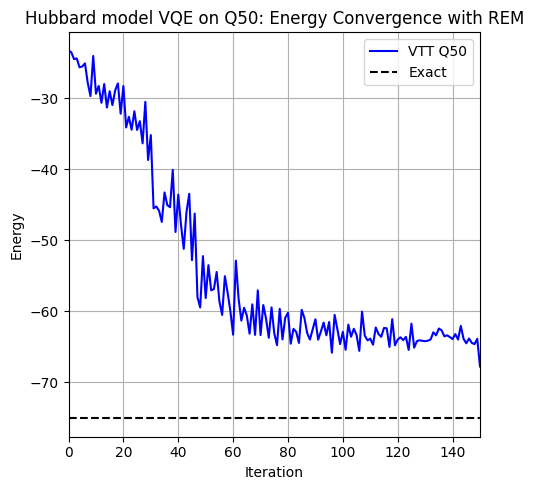

In [18]:
# --------- Plotting energy convergence ----------- #

f1 = plt.figure(figsize=(5,5))
ax1 = f1.add_subplot(1, 1, 1)
ax1.plot(energies1, color = 'blue', linewidth=1.5, label="VTT Q50")
plt.hlines(np.min(eigenvalues), xmin=0, xmax=201, label='Exact', color='black', linestyles='dashed', linewidth=1.5)
plt.xlim(0, 150)
plt.xlabel("Iteration")
plt.ylabel("Energy")
plt.title("Hubbard model VQE on Q50: Energy Convergence with REM")
plt.grid(True)
plt.tight_layout()
plt.legend()
f1.savefig("convergence_plot")
plt.show()